# Análisis de productividad y hábitos digitales

Trabajo Práctico Integrador — Tecnicatura Superior en Ciencia de Datos e IA.

Este notebook recorre el flujo completo de un proyecto de análisis de datos: generación y limpieza del dataset, análisis exploratorio, estadística inferencial (prueba de hipótesis) y dos modelos de Machine Learning (regresión y clasificación), con interpretación crítica de los resultados obtenidos.

Ver el README.md del repositorio para el resumen ejecutivo del proyecto.

In [1]:
import pandas as pd
import numpy as np

# Configuración de aleatoriedad
np.random.seed(42)

data = {
    'ID': range(1, 61),
    'Edad': np.random.randint(18, 55, 60),
    'Ocupacion': np.random.choice(['Estudiante', 'Empleado', 'Freelance', 'Desempleado'], 60),
    'Horas_Pantalla_Diaria': np.random.randint(2, 12, 60),
    'Usa_Tecnicas_Prod': np.random.choice(['Sí', 'No'], 60),
    'Principal_Distractor': np.random.choice(['Redes Sociales', 'Noticias', 'Videojuegos', 'Entorno'], 60),
    'Sesiones_Enfoque_Dia': np.random.randint(0, 6, 60),
}

# Generar Productividad Percibida basada en lógica de los datos
df = pd.DataFrame(data)
df['Productividad_Percibida'] = (df['Sesiones_Enfoque_Dia'] * 1.5) - (df['Horas_Pantalla_Diaria'] * 0.3) + np.random.randint(1, 5, 60)
df['Productividad_Percibida'] = df['Productividad_Percibida'].clip(1, 10).round(0).astype(int)

# Guardar a CSV para importar en Power BI
df.to_csv('encuesta_productividad.csv', index=False)
print("Archivo 'encuesta_productividad.csv' generado con 60 registros.")

Archivo 'encuesta_productividad.csv' generado con 60 registros.


In [2]:
df.head(60)

,ID,Edad,Ocupacion,Horas_Pantalla_Diaria,Usa_Tecnicas_Prod,Principal_Distractor,Sesiones_Enfoque_Dia,Productividad_Percibida
0,1,46,Empleado,9,No,Videojuegos,3,6
1,2,32,Freelance,7,No,Entorno,2,3
2,3,25,Desempleado,4,No,Videojuegos,0,1
3,4,38,Estudiante,2,Sí,Noticias,3,6
4,5,36,Empleado,4,No,Videojuegos,5,7
5,6,40,Desempleado,6,Sí,Videojuegos,3,5
6,7,28,Estudiante,4,Sí,Videojuegos,5,9
7,8,28,Desempleado,2,Sí,Entorno,2,6
8,9,41,Estudiante,6,Sí,Entorno,5,7
9,10,53,Empleado,11,No,Videojuegos,0,1


## Parte 1 — Obtención y descripción de los datos

### 1. Origen de los datos
Los datos son **sintéticos**: se generan en la primera celda del notebook con NumPy (semilla 42) y simulan las respuestas de una encuesta de 60 personas sobre hábitos digitales y productividad.

* La edad, la ocupación, las horas de pantalla, el uso de técnicas de productividad, el principal distractor y las sesiones de enfoque se asignan **al azar** dentro de rangos plausibles.
* La productividad percibida se calcula a partir de las sesiones de enfoque y las horas de pantalla, más un componente aleatorio, y se recorta al rango 1–10:

$$\text{Productividad} = 1{,}5 \cdot \text{Sesiones de enfoque} - 0{,}3 \cdot \text{Horas de pantalla} + \varepsilon, \qquad \varepsilon \in \{1, 2, 3, 4\}$$

Trabajar con datos simulados permite recorrer el flujo completo de un proyecto de datos de forma reproducible. Las conclusiones describen el comportamiento del dataset generado, no el de una población real.

### 2. Diccionario de variables

| Nombre de la Variable | Descripción Conceptual | Tipo de Dato (Python) | Clasificación Estadística |
| :--- | :--- | :--- | :--- |
| **`ID`** | Código unívoco de identificación del encuestado | `int64` | Cualitativa Nominal |
| **`Edad`** | Edad cronológica biológica del participante | `int64` | Cuantitativa Discreta |
| **`Ocupacion`** | Condición laboral o académica predominante | `object` (String) | Cualitativa Nominal Politómica |
| **`Horas_Pantalla_Diaria`** | Tiempo promedio neto diario frente a pantallas | `int64` | Cuantitativa Discreta (horas enteras) |
| **`Usa_Tecnicas_Prod`** | Adopción formal de hábitos o metodologías de foco | `object` (String) | Cualitativa Nominal Dicotómica |
| **`Principal_Distractor`** | Factor de interrupción con mayor impacto percibido | `object` (String) | Cualitativa Nominal Politómica |
| **`Sesiones_Enfoque_Dia`** | Cantidad de bloques diarios dedicados a *Deep Work* | `int64` | Cuantitativa Discreta |
| **`Productividad_Percibida`** | Autoevaluación del rendimiento en la jornada (1-10) | `int64` | Cuantitativa Ordinal (Escala de Rango) |

In [3]:
print("Dimensiones del dataset:", df.shape)
print("\nTipos de datos:")
print(df.dtypes)

Dimensiones del dataset: (60, 8)

Tipos de datos:
ID                         int64
Edad                       int64
Ocupacion                    str
Horas_Pantalla_Diaria      int64
Usa_Tecnicas_Prod            str
Principal_Distractor         str
Sesiones_Enfoque_Dia       int64
Productividad_Percibida    int64
dtype: object


## Parte 2 — Limpieza y preparación

### 1. Controles de calidad
Se verifican los valores faltantes, las filas duplicadas y las categorías de cada variable cualitativa, para detectar errores de escritura. Como el dataset se genera dentro del notebook no se esperan problemas de carga; los controles se incluyen como parte del procedimiento estándar.

### 2. Valores atípicos
Se aplica la regla de las 3 desviaciones estándar ($|x - \mu| > 3\sigma$) a las variables numéricas. Si aparecieran valores extremos en las horas de pantalla, se conservarían: una jornada de muchas horas frente a una pantalla es un comportamiento real de la población que se quiere describir, no un error de carga.

### 3. Variables derivadas
1. **`Indice_Enfoque`** (numérica continua): cantidad de sesiones de enfoque por hora de pantalla.
$$\text{Índice de Enfoque} = \frac{\text{Sesiones\_Enfoque\_Dia}}{\text{Horas\_Pantalla\_Diaria} + 0.1}$$
Valores altos indican más bloques de concentración por cada hora frente a una pantalla. El término 0,1 evita la división por cero.
2. **`Segmento_Edad`** (cualitativa ordinal): agrupa la edad en `Joven` (hasta 25 años), `Adulto Joven` (26 a 40) y `Adulto Maduro` (más de 40), para comparar grupos en el EDA.

In [4]:
# Controles de calidad
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
for col in ['Ocupacion', 'Usa_Tecnicas_Prod', 'Principal_Distractor']:
    print(f"Categorías de {col}: {sorted(df[col].unique())}")

# Valores atípicos: regla de las 3 desviaciones estándar
numericas = ['Edad', 'Horas_Pantalla_Diaria', 'Sesiones_Enfoque_Dia', 'Productividad_Percibida']
z = (df[numericas] - df[numericas].mean()) / df[numericas].std()
print("\nValores con |z| > 3 por variable:")
print((z.abs() > 3).sum().to_string())

# Variables derivadas
df['Indice_Enfoque'] = (df['Sesiones_Enfoque_Dia'] / (df['Horas_Pantalla_Diaria'] + 0.1)).round(2)
df['Segmento_Edad'] = pd.cut(df['Edad'], bins=[0, 25, 40, 120],
                             labels=['Joven', 'Adulto Joven', 'Adulto Maduro']).astype(str)
df[['Edad', 'Segmento_Edad', 'Sesiones_Enfoque_Dia', 'Horas_Pantalla_Diaria', 'Indice_Enfoque']].head()

Valores faltantes: 0
Filas duplicadas: 0
Categorías de Ocupacion: ['Desempleado', 'Empleado', 'Estudiante', 'Freelance']
Categorías de Usa_Tecnicas_Prod: ['No', 'Sí']
Categorías de Principal_Distractor: ['Entorno', 'Noticias', 'Redes Sociales', 'Videojuegos']

Valores con |z| > 3 por variable:
Edad                       0
Horas_Pantalla_Diaria      0
Sesiones_Enfoque_Dia       0
Productividad_Percibida    0


,Edad,Segmento_Edad,Sesiones_Enfoque_Dia,Horas_Pantalla_Diaria,Indice_Enfoque
0,46,Adulto Maduro,3,9,0.33
1,32,Adulto Joven,2,7,0.28
2,25,Joven,0,4,0.00
3,38,Adulto Joven,3,2,1.43
4,36,Adulto Joven,5,4,1.22


## Parte 3 — Análisis exploratorio de datos (EDA)

### 1. Estadísticas descriptivas
La tabla que se imprime debajo de los gráficos resume las variables numéricas:

* **Edad:** media de 35 años, entre 19 y 54. La mitad de la muestra tiene entre 25,75 y 43 años.
* **Horas de pantalla:** media de 6,78 horas diarias (desvío 2,95), entre 2 y 11 horas.
* **Sesiones de enfoque:** media de 2,65 por día. El 25 % de las personas tiene una sesión o ninguna; el máximo es 5.
* **Productividad percibida:** media de 4,55 y mediana de 4,5 sobre 10, con un desvío alto (2,68).

### 2. Las 6 visualizaciones

**Gráfico 1 — Distribución de la productividad percibida.** La distribución es dispersa y ocupa toda la escala. El valor más frecuente es el mínimo: 12 de las 60 personas marcaron 1, efecto del recorte de la fórmula en el límite inferior.

**Gráfico 2 — Sesiones de enfoque vs. productividad.** Es la relación más clara del dataset: a más sesiones de enfoque, mayor productividad. Es esperable, porque la productividad se generó a partir de esa variable. El color indica si la persona usa técnicas de productividad; quienes las usan tienen en promedio algo más de sesiones (3,0 contra 2,3).

**Gráfico 3 — Densidad de las horas de pantalla.** Los valores se reparten entre 2 y 11 horas, con mayor concentración entre las 7 y las 10 horas diarias.

**Gráfico 4 — Productividad según el principal distractor.** Las medianas van de 3 (Redes Sociales) a 6 (Noticias), con Entorno y Videojuegos en 5. Como el distractor se asignó al azar, estas diferencias reflejan la variabilidad de una muestra chica (entre 9 y 21 personas por grupo) y no un efecto real.

**Gráfico 5 — Índice de enfoque por segmento de edad.** El segmento Adulto Joven tiene el índice promedio más alto (0,67), seguido de Joven (0,48) y Adulto Maduro (0,36). Con grupos de 15 a 24 personas y variables asignadas al azar, la diferencia no permite sacar conclusiones generacionales.

**Gráfico 6 — Uso de técnicas de productividad por ocupación.** Los Desempleados (59 %) y los Freelance (53 %) son los que más usan técnicas de gestión del tiempo; los Empleados, los que menos (25 %). Al igual que en los gráficos 4 y 5, las diferencias surgen de una asignación aleatoria.

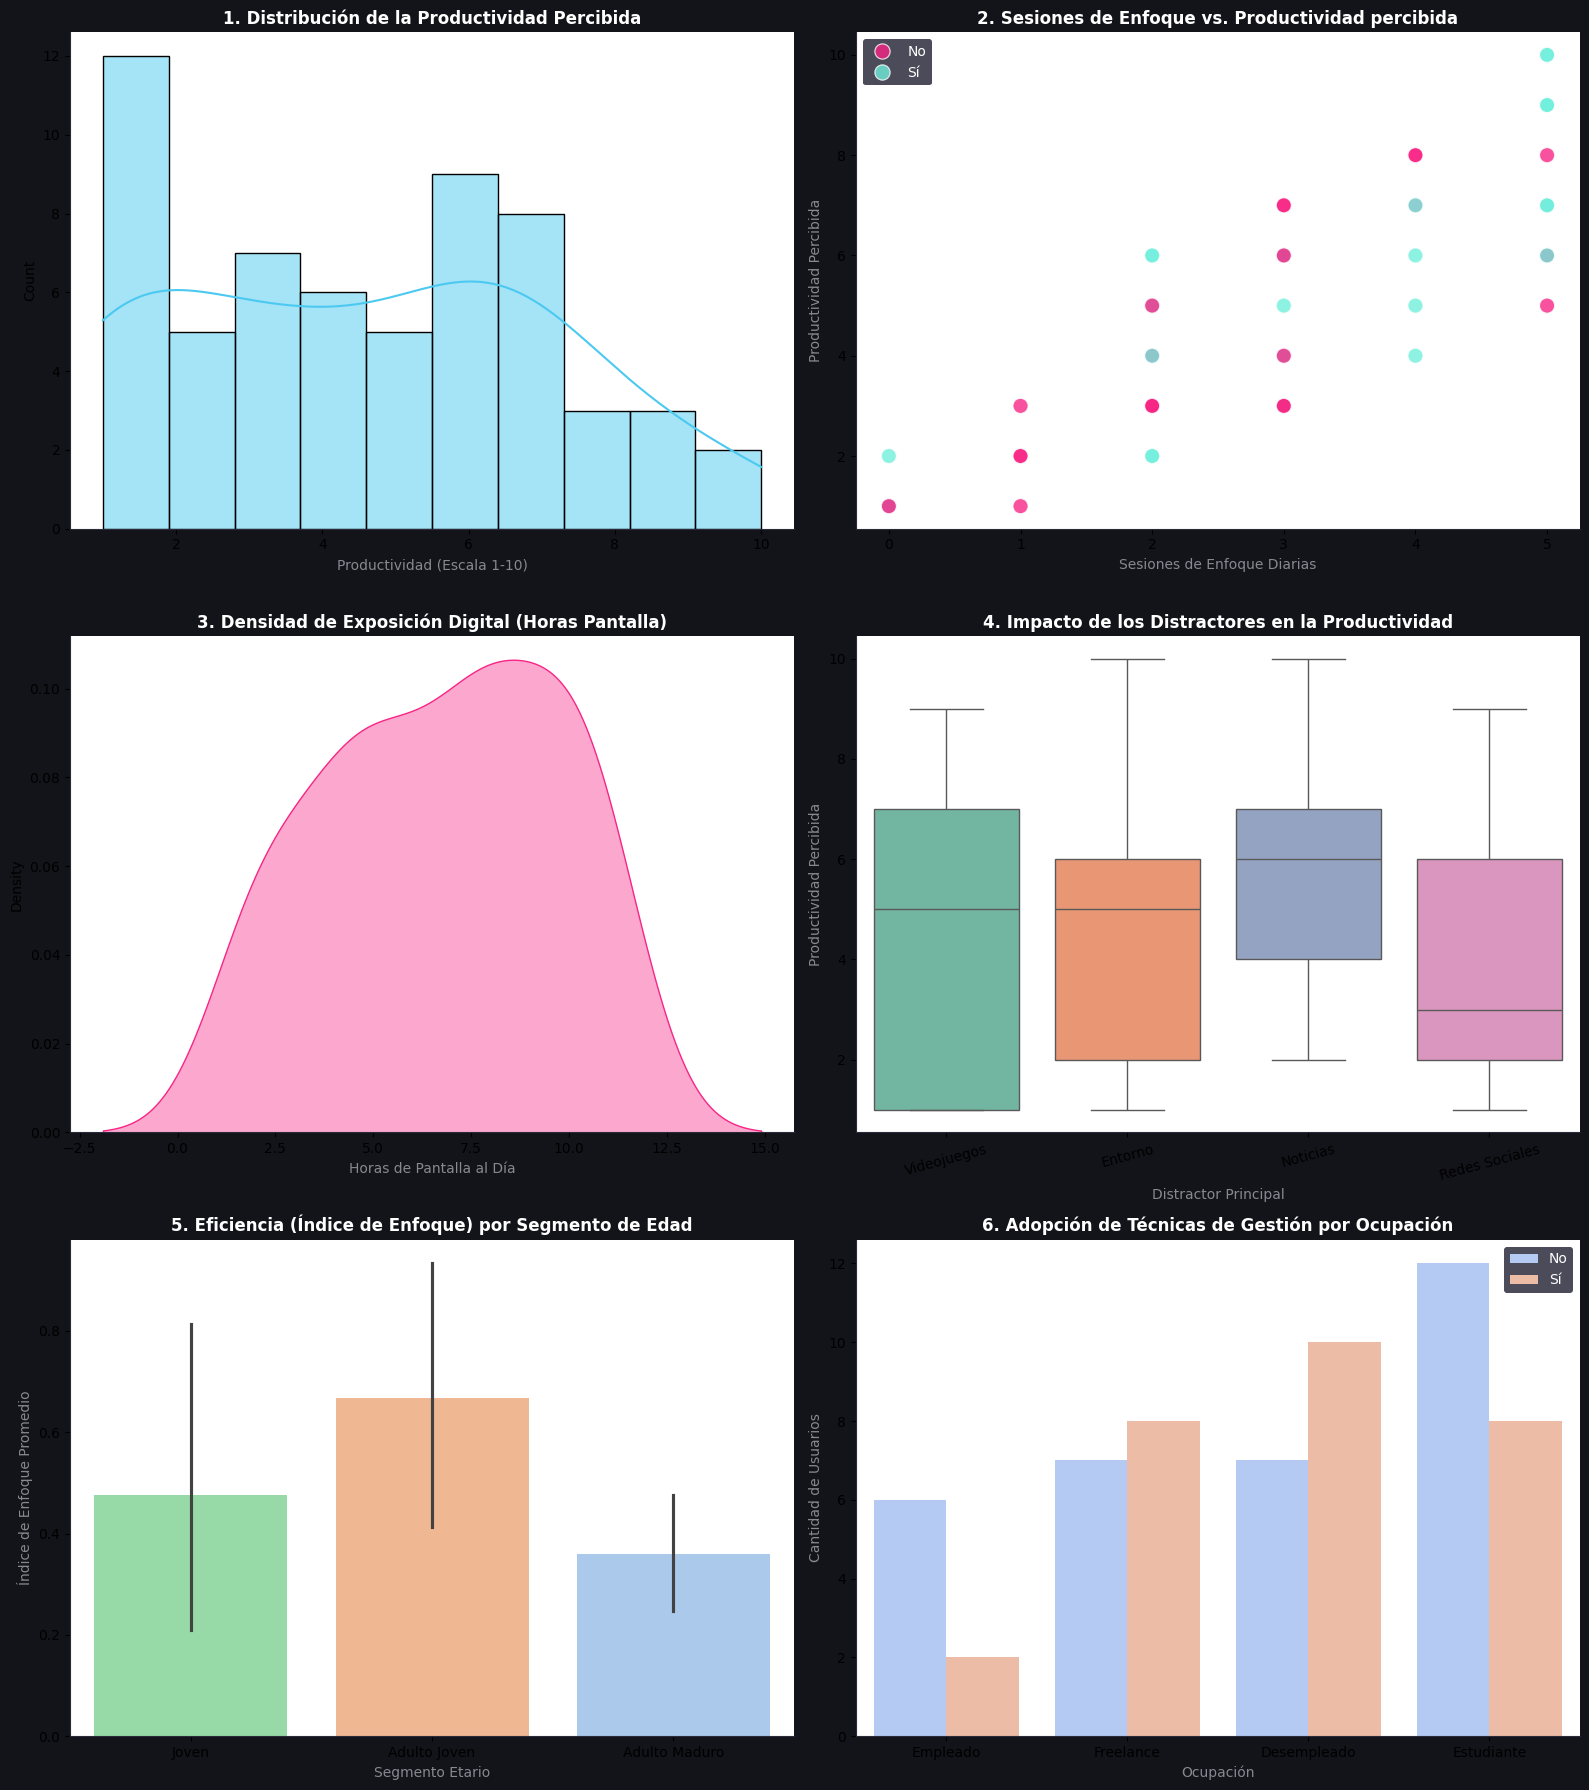

        Edad  Horas_Pantalla_Diaria  Sesiones_Enfoque_Dia  \
count  60.00                  60.00                 60.00   
mean   35.00                   6.78                  2.65   
std    10.54                   2.95                  1.80   
min    19.00                   2.00                  0.00   
25%    25.75                   4.00                  1.00   
50%    35.00                   7.00                  3.00   
75%    43.00                   9.25                  4.00   
max    54.00                  11.00                  5.00   

       Productividad_Percibida  
count                    60.00  
mean                      4.55  
std                       2.68  
min                       1.00  
25%                       2.00  
50%                       4.50  
75%                       7.00  
max                      10.00  


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Lienzo de 3 filas x 2 columnas para los 6 gráficos
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.patch.set_facecolor('#13131a')

# ------------------------------------------------------------------
# GRÁFICO 1: Distribución del Target (Productividad Percibida)
# ------------------------------------------------------------------
sns.histplot(data=df, x='Productividad_Percibida', kde=True, bins=10, color='#4cc9f0', ax=axes[0, 0])
axes[0, 0].set_title('1. Distribución de la Productividad Percibida', fontsize=12, weight='bold', color='white')
axes[0, 0].set_xlabel('Productividad (Escala 1-10)', color='#888891')

# ------------------------------------------------------------------
# GRÁFICO 2: Relación Crítica - Foco vs Productividad (Scatter Plot)
# ------------------------------------------------------------------
sns.scatterplot(data=df, x='Sesiones_Enfoque_Dia', y='Productividad_Percibida', hue='Usa_Tecnicas_Prod',
                palette={'Sí': '#72efdd', 'No': '#f72585'}, s=120, alpha=0.8, ax=axes[0, 1])
axes[0, 1].set_title('2. Sesiones de Enfoque vs. Productividad percibida', fontsize=12, weight='bold', color='white')
axes[0, 1].set_xlabel('Sesiones de Enfoque Diarias', color='#888891')
axes[0, 1].set_ylabel('Productividad Percibida', color='#888891')
axes[0, 1].legend(facecolor='#1e1e2f', edgecolor='none', labelcolor='white')

# ------------------------------------------------------------------
# GRÁFICO 3: Exposición Digital - Horas de Pantalla Diaria
# ------------------------------------------------------------------
sns.kdeplot(data=df, x='Horas_Pantalla_Diaria', fill=True, color='#f72585', alpha=0.4, ax=axes[1, 0])
axes[1, 0].set_title('3. Densidad de Exposición Digital (Horas Pantalla)', fontsize=12, weight='bold', color='white')
axes[1, 0].set_xlabel('Horas de Pantalla al Día', color='#888891')

# ------------------------------------------------------------------
# GRÁFICO 4: Comparación - Impacto del Distractor Principal (Boxplot)
# ------------------------------------------------------------------
sns.boxplot(data=df, x='Principal_Distractor', y='Productividad_Percibida', hue='Principal_Distractor',
            palette='Set2', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('4. Impacto de los Distractores en la Productividad', fontsize=12, weight='bold', color='white')
axes[1, 1].set_xlabel('Distractor Principal', color='#888891')
axes[1, 1].set_ylabel('Productividad Percibida', color='#888891')
axes[1, 1].tick_params(axis='x', rotation=15)

# ------------------------------------------------------------------
# GRÁFICO 5: Análisis Generacional (Segmento de Edad vs Índice de Enfoque)
# ------------------------------------------------------------------
sns.barplot(data=df, x='Segmento_Edad', y='Indice_Enfoque', hue='Segmento_Edad',
            palette='pastel', legend=False, order=['Joven', 'Adulto Joven', 'Adulto Maduro'], ax=axes[2, 0])
axes[2, 0].set_title('5. Eficiencia (Índice de Enfoque) por Segmento de Edad', fontsize=12, weight='bold', color='white')
axes[2, 0].set_xlabel('Segmento Etario', color='#888891')
axes[2, 0].set_ylabel('Índice de Enfoque Promedio', color='#888891')

# ------------------------------------------------------------------
# GRÁFICO 6: Análisis por Ocupación y Técnicas de Productividad
# ------------------------------------------------------------------
sns.countplot(data=df, x='Ocupacion', hue='Usa_Tecnicas_Prod', palette='coolwarm', ax=axes[2, 1])
axes[2, 1].set_title('6. Adopción de Técnicas de Gestión por Ocupación', fontsize=12, weight='bold', color='white')
axes[2, 1].set_xlabel('Ocupación', color='#888891')
axes[2, 1].set_ylabel('Cantidad de Usuarios', color='#888891')
axes[2, 1].legend(facecolor='#1e1e2f', edgecolor='none', labelcolor='white')

# Ajustes generales de limpieza visual sobre los bordes
for row in axes:
    for ax in row:
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_color('#2a2a3b')
        ax.spines['bottom'].set_color('#2a2a3b')

plt.tight_layout()
plt.show()

print(df[['Edad', 'Horas_Pantalla_Diaria', 'Sesiones_Enfoque_Dia', 'Productividad_Percibida']].describe().round(2))

## Parte 4 — Estadística, probabilidad e hipótesis

### 1. Medidas de tendencia central y dispersión
* **Productividad percibida:** media de 4,55, mediana de 4,5 y desvío estándar de 2,68, una dispersión alta para una escala de 1 a 10. La **moda es 1**, el valor mínimo de la escala.
* **Principal distractor:** la categoría más frecuente es **Entorno** (21 de 60 personas).

### 2. Probabilidad simple y condicional
* **Probabilidad simple:** la probabilidad de que una persona elegida al azar use técnicas de productividad es
$$P(\text{Usa\_Tecnicas\_Prod} = \text{'Sí'}) = \frac{28}{60} = 0{,}4667$$
* **Probabilidad condicional:** la probabilidad de tener una productividad alta (≥ 6) entre quienes usan técnicas es
$$P(\text{Productividad} \ge 6 \mid \text{Usa\_Tecnicas\_Prod} = \text{'Sí'}) = \frac{14}{28} = 0{,}50$$

Para interpretarla hay que compararla con las referencias que calcula la celda siguiente: la probabilidad de productividad alta es de 41,7 % en toda la muestra y de 34,4 % entre quienes no usan técnicas. La diferencia existe, pero es moderada y se basa en grupos chicos (28 y 32 personas). Además, en este dataset el uso de técnicas se asignó al azar, por lo que la diferencia se debe a la variabilidad de la muestra.

### 3. Prueba de hipótesis: correlación de Pearson
Se evalúa si existe una relación lineal entre las sesiones de enfoque y la productividad percibida.

* **Hipótesis nula ($H_0$):** $\rho = 0$, no existe relación lineal.
* **Hipótesis alternativa ($H_1$):** $\rho \neq 0$, existe relación lineal.

**Resultado:** $r = 0{,}8781$, con un p-value de $3{,}23 \times 10^{-20}$. Como el p-value es mucho menor que $\alpha = 0{,}05$, **se rechaza $H_0$**: hay una correlación positiva fuerte entre ambas variables. El resultado es coherente con la forma en que se generaron los datos, donde la productividad depende directamente de las sesiones de enfoque.

In [6]:
import pandas as pd
from scipy import stats

# 1. Medidas de Tendencia Central y Dispersión
media_prod = df['Productividad_Percibida'].mean()
mediana_prod = df['Productividad_Percibida'].median()
moda_prod = df['Productividad_Percibida'].mode()[0]
desvio_prod = df['Productividad_Percibida'].std()
moda_distractor = df['Principal_Distractor'].mode()[0]

print(f"Productividad -> Media: {media_prod:.2f} | Mediana: {mediana_prod:.2f} | Moda: {moda_prod:.2f} | Desvío Estándar: {desvio_prod:.2f}")
print(f"Moda del Principal Distractor: '{moda_distractor}'")

# 2. Cálculos de Probabilidad
# Probabilidad Simple: P(Usa Técnicas = Sí)
total_casos = len(df)
casos_tecnicas = len(df[df['Usa_Tecnicas_Prod'] == 'Sí'])
p_simple = casos_tecnicas / total_casos

# Probabilidad Condicional: P(Productividad Alta [>=6] | Usa Técnicas = Sí)
df_si_tecnicas = df[df['Usa_Tecnicas_Prod'] == 'Sí']
casos_alta_prod_dado_si = len(df_si_tecnicas[df_si_tecnicas['Productividad_Percibida'] >= 6])
p_condicional = casos_alta_prod_dado_si / len(df_si_tecnicas)

# Referencias para comparar: toda la muestra y quienes no usan técnicas
p_alta_total = (df['Productividad_Percibida'] >= 6).mean()
df_no_tecnicas = df[df['Usa_Tecnicas_Prod'] == 'No']
p_alta_no = (df_no_tecnicas['Productividad_Percibida'] >= 6).mean()

print(f"\nCasos Totales: {total_casos} | Casos Usan Técnicas: {casos_tecnicas}")
print(f"P(Usa_Tecnicas_Prod = Sí) = {p_simple:.4f} ({p_simple*100:.2f}%)")
print(f"P(Productividad >= 6 | Usa_Tecnicas_Prod = Sí) = {p_condicional:.4f} ({p_condicional*100:.2f}%)")
print(f"P(Productividad >= 6) en toda la muestra = {p_alta_total:.4f} ({p_alta_total*100:.2f}%)")
print(f"P(Productividad >= 6 | Usa_Tecnicas_Prod = No) = {p_alta_no:.4f} ({p_alta_no*100:.2f}%)")

# 3. Test de Hipótesis de Pearson (Foco vs Productividad)
r_corr, p_value = stats.pearsonr(df['Sesiones_Enfoque_Dia'], df['Productividad_Percibida'])
print(f"\nTest de Pearson -> Coeficiente r: {r_corr:.4f} | p-value: {p_value:.4e}")

Productividad -> Media: 4.55 | Mediana: 4.50 | Moda: 1.00 | Desvío Estándar: 2.68
Moda del Principal Distractor: 'Entorno'

Casos Totales: 60 | Casos Usan Técnicas: 28
P(Usa_Tecnicas_Prod = Sí) = 0.4667 (46.67%)
P(Productividad >= 6 | Usa_Tecnicas_Prod = Sí) = 0.5000 (50.00%)
P(Productividad >= 6) en toda la muestra = 0.4167 (41.67%)
P(Productividad >= 6 | Usa_Tecnicas_Prod = No) = 0.3438 (34.38%)

Test de Pearson -> Coeficiente r: 0.8781 | p-value: 3.2278e-20


## Parte 5 — Modelado

### 1. Partición de los datos
Se usa una partición única (*holdout*): **80 % para entrenamiento** (48 registros) y **20 % para prueba** (12 registros), con `random_state=42` para que el resultado sea reproducible. Las variables categóricas (`Ocupacion` y `Principal_Distractor`) se codifican con One-Hot Encoding, eliminando una categoría de cada una (`drop='first'`).

### 2. Modelo A: regresión lineal múltiple
* **Variable objetivo:** `Productividad_Percibida`.
* **Resultados en prueba:** $R^2 = 0{,}832$ y MAE = 0,68.

El modelo explica el 83 % de la variabilidad de la productividad, con un error promedio de menos de un punto en la escala de 1 a 10. El buen ajuste es esperable: la productividad se generó como una combinación lineal de las sesiones de enfoque y las horas de pantalla, que el modelo recupera.

### 3. Modelo B: regresión logística
* **Variable objetivo:** `Usa_Tecnicas_Prod_Bin` (0 = no usa técnicas, 1 = usa).
* **Resultados en prueba:** accuracy de 41,7 %. El modelo predijo "No Usa" para los 12 casos de prueba, por lo que el recall de la clase "Sí Usa" es 0.

El modelo no aprende un patrón útil. La causa principal es que la variable objetivo se generó al azar, sin relación con las demás variables, así que no hay señal que capturar. A eso se suma el tamaño de la muestra (48 registros de entrenamiento y 12 de prueba) frente a la cantidad de variables codificadas. El caso muestra por qué no alcanza con mirar el accuracy y conviene revisar la precisión y el recall de cada clase.

### 4. Conclusión
El notebook recorre el flujo completo de un proyecto de datos: generación y control del dataset, análisis exploratorio, inferencia estadística y modelado. Los resultados describen un dataset simulado: la relación entre enfoque y productividad aparece porque está incorporada en la generación de los datos, y las variables asignadas al azar no muestran efectos reales.

In [7]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, classification_report

# 1. Variable binaria de uso de técnicas (1 = Sí, 0 = No)
df['Usa_Tecnicas_Prod_Bin'] = df['Usa_Tecnicas_Prod'].map({'Sí': 1, 'No': 0})

# 2. Codificamos las variables categoricas (Ocupacion y Distractor) usando One-Hot Encoding
encoder = OneHotEncoder(drop='first', sparse_output=False)
X_categorical = encoder.fit_transform(df[['Ocupacion', 'Principal_Distractor']])
categorical_cols = encoder.get_feature_names_out(['Ocupacion', 'Principal_Distractor'])
df_categorical = pd.DataFrame(X_categorical, columns=categorical_cols, index=df.index)

# 3. Consolidamos el DataFrame numerico final para los modelos
df_modelos = pd.concat([
    df[['Edad', 'Horas_Pantalla_Diaria', 'Sesiones_Enfoque_Dia', 'Indice_Enfoque', 'Usa_Tecnicas_Prod_Bin', 'Productividad_Percibida']],
    df_categorical
], axis=1)

# ==================================================================
# MODELO A: Regresion Lineal Multiple (Prediccion de Productividad)
# ==================================================================
print("\n--- MODELO A: REGRESION LINEAL MULTIPLE ---")
X_reg = df_modelos.drop(columns=['Productividad_Percibida'])
y_reg = df_modelos['Productividad_Percibida']

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

modelo_lineal = LinearRegression()
modelo_lineal.fit(X_train_r, y_train_r)
y_pred_r = modelo_lineal.predict(X_test_r)

print(f"Coeficiente de Determinacion (R2): {r2_score(y_test_r, y_pred_r):.4f}")
print(f"Error Absoluto Medio (MAE): {mean_absolute_error(y_test_r, y_pred_r):.4f}")

# ==================================================================
# MODELO B: Regresion Logistica (Clasificacion Binaria de Tecnicas)
# ==================================================================
print("\n--- MODELO B: CLASIFICACION BINARIA (REGRESION LOGISTICA) ---")
X_cls = df_modelos.drop(columns=['Usa_Tecnicas_Prod_Bin'])
y_cls = df_modelos['Usa_Tecnicas_Prod_Bin']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_cls, y_cls, test_size=0.2, random_state=42)

modelo_logistico = LogisticRegression(max_iter=1000)
modelo_logistico.fit(X_train_c, y_train_c)
y_pred_c = modelo_logistico.predict(X_test_c)

print(f"Exactitud Global (Accuracy): {accuracy_score(y_test_c, y_pred_c):.4f}")
print("\nReporte de Clasificacion Detallado:")
print(classification_report(y_test_c, y_pred_c, target_names=['No Usa', 'Sí Usa'], zero_division=0))


--- MODELO A: REGRESION LINEAL MULTIPLE ---


Coeficiente de Determinacion (R2): 0.8320
Error Absoluto Medio (MAE): 0.6806

--- MODELO B: CLASIFICACION BINARIA (REGRESION LOGISTICA) ---
Exactitud Global (Accuracy): 0.4167

Reporte de Clasificacion Detallado:


              precision    recall  f1-score   support

      No Usa       0.42      1.00      0.59         5
      Sí Usa       0.00      0.00      0.00         7

    accuracy                           0.42        12
   macro avg       0.21      0.50      0.29        12
weighted avg       0.17      0.42      0.25        12

